# Airline Reviews Analysis Using Natural Language Processing

## Project Purpose

Airlines receive large volumes of passenger reviews containing detailed information
about customer experiences. Manually reading these reviews can be time-consuming.

The purpose of this project is to determine whether the text contained in passenger
reviews can be used to identify specific airline service problems.

Seven service categories are investigated:

1. Seat Comfort
2. Cabin Staff Service
3. Food & Beverages
4. Ground Service
5. Inflight Entertainment
6. Wi-Fi & Connectivity
7. Value for Money

Service ratings are converted into binary problem labels and Natural Language
Processing (NLP) techniques are used to predict these labels from passenger review text.

### Research Questions

1. Can passenger review text be used to identify specific airline service problems?
2. Which service categories can be predicted most accurately from review text?
3. What words and phrases are commonly associated with passenger dissatisfaction?
4. How does class imbalance affect prediction performance across service categories?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from wordcloud import WordCloud

# Download NLTK resources if necessary
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\vinay\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\vinay\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [2]:
!pip install wordcloud

In [3]:
#Load Dataset

df = pd.read_csv("Airline_review.csv")

df.head()

,Unnamed: 0,Airline Name,Overall_Rating,Review_Title,Review Date,Verified,Review,Aircraft,Type Of Traveller,Seat Type,Route,Date Flown,Seat Comfort,Cabin Staff Service,Food & Beverages,Ground Service,Inflight Entertainment,Wifi & Connectivity,Value For Money,Recommended
0,0,AB Aviation,9,"""pretty decent airline""",11th November 2019,True,Moroni to Moheli. Turned out to be a pretty ...,NaN,Solo Leisure,Economy Class,Moroni to Moheli,November 2019,4.0,5.0,4.0,4.0,NaN,NaN,3.0,yes
1,1,AB Aviation,1,"""Not a good airline""",25th June 2019,True,Moroni to Anjouan. It is a very small airline...,E120,Solo Leisure,Economy Class,Moroni to Anjouan,June 2019,2.0,2.0,1.0,1.0,NaN,NaN,2.0,no
2,2,AB Aviation,1,"""flight was fortunately short""",25th June 2019,True,Anjouan to Dzaoudzi. A very small airline an...,Embraer E120,Solo Leisure,Economy Class,Anjouan to Dzaoudzi,June 2019,2.0,1.0,1.0,1.0,NaN,NaN,2.0,no
3,3,Adria Airways,1,"""I will never fly again with Adria""",28th September 2019,False,Please do a favor yourself and do not fly wi...,NaN,Solo Leisure,Economy Class,Frankfurt to Pristina,September 2019,1.0,1.0,NaN,1.0,NaN,NaN,1.0,no
4,4,Adria Airways,1,"""it ruined our last days of holidays""",24th September 2019,True,Do not book a flight with this airline! My fr...,NaN,Couple Leisure,Economy Class,Sofia to Amsterdam via Ljubljana,September 2019,1.0,1.0,1.0,1.0,1.0,1.0,1.0,no


In [4]:
print("Original dataset shape:", df.shape)

df.info()

Original dataset shape: (23171, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23171 entries, 0 to 23170
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              23171 non-null  int64  
 1   Airline Name            23171 non-null  object 
 2   Overall_Rating          23171 non-null  object 
 3   Review_Title            23171 non-null  object 
 4   Review Date             23171 non-null  object 
 5   Verified                23171 non-null  bool   
 6   Review                  23171 non-null  object 
 7   Aircraft                7129 non-null   object 
 8   Type Of Traveller       19433 non-null  object 
 9   Seat Type               22075 non-null  object 
 10  Route                   19343 non-null  object 
 11  Date Flown              19417 non-null  object 
 12  Seat Comfort            19016 non-null  float64
 13  Cabin Staff Service     18911 non-null  float64
 14  Fo

### Data Cleaning

In [5]:
# Remove unnecessary index column
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print("Dataset shape after removing index column:", df.shape)

Dataset shape after removing index column: (23171, 19)


###  Check for Duplicates

In [6]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 120


In [7]:
# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (23051, 19)
Remaining duplicate rows: 0


### Missing-Value Analysis

In [8]:
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percent': (df.isnull().sum() / len(df)) * 100
})

missing_summary = missing_summary[
    missing_summary['Missing Count'] > 0
].sort_values(
    by='Missing Percent',
    ascending=False
)

missing_summary.round(2)

,Missing Count,Missing Percent
Wifi & Connectivity,17133,74.33
Aircraft,15924,69.08
Inflight Entertainment,12224,53.03
Food & Beverages,8555,37.11
Ground Service,4682,20.31
Cabin Staff Service,4149,18.00
Seat Comfort,4044,17.54
Route,3716,16.12
Date Flown,3642,15.80
Type Of Traveller,3627,15.73


>> Several service-rating variables contain substantial missing data.Missing ratings were not replaced with average values because a missing rating may indicate that the passenger did not use or evaluate that service. Imputing an average
rating could therefore introduce artificial information into the target variables. Only reviews containing a usable rating for a particular service category are used
when that category is modeled.

In [9]:
print(df['Overall_Rating'].value_counts(dropna=False))

Overall_Rating
1    11587
2     2294
9     1768
8     1756
3     1353
7     1193
4      853
5      826
n      749
6      672
Name: count, dtype: int64


In [10]:
# Find records with invalid Overall_Rating values

numeric_rating = pd.to_numeric(
    df['Overall_Rating'],
    errors='coerce'
)

invalid_mask = numeric_rating.isna() & df['Overall_Rating'].notna()

invalid_ratings = df[invalid_mask]

print("Number of invalid Overall_Rating records:", len(invalid_ratings))

Number of invalid Overall_Rating records: 749


In [11]:
print("Recommended values for invalid ratings:")
print(
    invalid_ratings['Recommended']
    .value_counts(dropna=False)
)

print("\nMissing service ratings among invalid Overall_Rating records:")

service_columns = [
    'Seat Comfort',
    'Cabin Staff Service',
    'Food & Beverages',
    'Ground Service',
    'Inflight Entertainment',
    'Wifi & Connectivity',
    'Value For Money'
]

print(
    invalid_ratings[service_columns]
    .isnull()
    .sum()
)

Recommended values for invalid ratings:
Recommended
no     745
yes      4
Name: count, dtype: int64

Missing service ratings among invalid Overall_Rating records:
Seat Comfort              572
Cabin Staff Service       572
Food & Beverages          572
Ground Service            749
Inflight Entertainment    573
Wifi & Connectivity       749
Value For Money           433
dtype: int64


>>The invalid Overall_Rating value "n" should not be interpreted as a numeric score.There is no evidence that "n" represents a rating such as 10. Instead, these values are converted to missing values.The rows themselves are retained because the main objective of this project is to analyze review text and service-specific ratings. Some of these records still contain
useful service-rating and review information.

In [12]:
# Convert Overall Rating to Numeric

df['Overall_Rating'] = pd.to_numeric(
    df['Overall_Rating'],
    errors='coerce'
)

print(df['Overall_Rating'].value_counts(dropna=False).sort_index())

Overall_Rating
1.0    11587
2.0     2294
3.0     1353
4.0      853
5.0      826
6.0      672
7.0     1193
8.0     1756
9.0     1768
NaN      749
Name: count, dtype: int64


In [13]:
#Clean Review Dates

# Remove ordinal suffixes such as 1st, 2nd, 3rd, 4th

df['Review Date'] = (
    df['Review Date']
    .astype(str)
    .str.replace(
        r'(\d+)(st|nd|rd|th)',
        r'\1',
        regex=True
    )
)

df['Review Date'] = pd.to_datetime(
    df['Review Date'],
    errors='coerce'
)

print("Earliest Review Date:", df['Review Date'].min())
print("Latest Review Date:", df['Review Date'].max())

Earliest Review Date: 2002-01-06 00:00:00
Latest Review Date: 2023-07-27 00:00:00


In [14]:
#Check Categorical Variables

categorical_columns = [
    'Verified',
    'Type Of Traveller',
    'Seat Type',
    'Recommended'
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts(dropna=False))


 Verified
Verified
True     12319
False    10732
Name: count, dtype: int64

 Type Of Traveller
Type Of Traveller
Solo Leisure      7116
Couple Leisure    5262
Family Leisure    4352
NaN               3627
Business          2694
Name: count, dtype: int64

 Seat Type
Seat Type
Economy Class      19133
Business Class      2097
NaN                  989
Premium Economy      646
First Class          186
Name: count, dtype: int64

 Recommended
Recommended
no     15251
yes     7800
Name: count, dtype: int64


In [15]:
#Convert Recommended to Binary

df['Recommended'] = (
    df['Recommended']
    .astype(str)
    .str.lower()
    .str.strip()
)

df['Recommended'] = df['Recommended'].map({
    'yes': 1,
    'no': 0
})

print(df['Recommended'].value_counts(dropna=False))

Recommended
0    15251
1     7800
Name: count, dtype: int64


In [16]:
#Service Rating Distributions
service_columns = [
    'Seat Comfort',
    'Cabin Staff Service',
    'Food & Beverages',
    'Ground Service',
    'Inflight Entertainment',
    'Wifi & Connectivity',
    'Value For Money'
]

for column in service_columns:

    print("\n" + "=" * 50)
    print(column)
    print("=" * 50)

    print(
        df[column]
        .value_counts(normalize=True, dropna=True)
        .sort_index()
        .mul(100)
        .round(2)
    )


Seat Comfort
Seat Comfort
0.0     0.76
1.0    33.32
2.0    15.09
3.0    19.02
4.0    17.77
5.0    14.04
Name: proportion, dtype: float64

Cabin Staff Service
Cabin Staff Service
0.0     0.69
1.0    31.57
2.0    12.49
3.0    15.05
4.0    15.55
5.0    24.65
Name: proportion, dtype: float64

Food & Beverages
Food & Beverages
0.0     1.74
1.0    36.44
2.0    13.57
3.0    16.71
4.0    16.09
5.0    15.46
Name: proportion, dtype: float64

Ground Service
Ground Service
1.0    51.54
2.0     8.68
3.0     9.80
4.0    12.78
5.0    17.19
Name: proportion, dtype: float64

Inflight Entertainment
Inflight Entertainment
0.0     4.81
1.0    44.73
2.0    11.80
3.0    15.70
4.0    12.27
5.0    10.68
Name: proportion, dtype: float64

Wifi & Connectivity
Wifi & Connectivity
0.0     0.02
1.0    68.59
2.0     8.09
3.0     8.23
4.0     6.76
5.0     8.31
Name: proportion, dtype: float64

Value For Money
Value For Money
0.0     0.62
1.0    45.87
2.0    11.05
3.0     9.96
4.0    15.27
5.0    17.23
Name: proporti

The service variables use a five-point rating scale.For this study:
- Ratings 1–2 represent a service problem.
- Rating 3 represents a neutral evaluation.
- Ratings 4–5 represent no service problem.
- Missing values represent unknown or unavailable evaluations.

Neutral values are excluded rather than forced into either the problem or no-problem
category.

In [17]:
#Create Binary Service Problem Labels

def create_problem_label(rating):

    if pd.isna(rating):
        return np.nan

    elif rating <= 2:
        return 1        # Service problem

    elif rating >= 4:
        return 0        # No service problem

    else:
        return np.nan   # Rating 3 = neutral

In [18]:
df['Seat_Comfort_Problem'] = (
    df['Seat Comfort']
    .apply(create_problem_label)
)

df['Cabin_Staff_Problem'] = (
    df['Cabin Staff Service']
    .apply(create_problem_label)
)

df['Food_Beverage_Problem'] = (
    df['Food & Beverages']
    .apply(create_problem_label)
)

df['Ground_Service_Problem'] = (
    df['Ground Service']
    .apply(create_problem_label)
)

df['Inflight_Entertainment_Problem'] = (
    df['Inflight Entertainment']
    .apply(create_problem_label)
)

df['Wifi_Problem'] = (
    df['Wifi & Connectivity']
    .apply(create_problem_label)
)

df['Value_For_Money_Problem'] = (
    df['Value For Money']
    .apply(create_problem_label)
)

print("Binary service-problem labels created.")

Binary service-problem labels created.


In [19]:
#Define Target Variables


target_columns = [
    'Seat_Comfort_Problem',
    'Cabin_Staff_Problem',
    'Food_Beverage_Problem',
    'Ground_Service_Problem',
    'Inflight_Entertainment_Problem',
    'Wifi_Problem',
    'Value_For_Money_Problem'
]

In [20]:
#Display
for target in target_columns:

    print("\n" + target)

    print(
        df[target]
        .value_counts(dropna=False)
    )


Seat_Comfort_Problem
Seat_Comfort_Problem
1.0    9345
NaN    7660
0.0    6046
Name: count, dtype: int64

Cabin_Staff_Problem
Cabin_Staff_Problem
1.0    8458
0.0    7599
NaN    6994
Name: count, dtype: int64

Food_Beverage_Problem
Food_Beverage_Problem
NaN    10977
1.0     7501
0.0     4573
Name: count, dtype: int64

Ground_Service_Problem
Ground_Service_Problem
1.0    11063
NaN     6483
0.0     5505
Name: count, dtype: int64

Inflight_Entertainment_Problem
Inflight_Entertainment_Problem
NaN    13924
1.0     6642
0.0     2485
Name: count, dtype: int64

Wifi_Problem
Wifi_Problem
NaN    17620
1.0     4539
0.0      892
Name: count, dtype: int64

Value_For_Money_Problem
Value_For_Money_Problem
1.0    12711
0.0     7181
NaN     3159
Name: count, dtype: int64


In [21]:
#Create Summary of Usable Data


target_summary = []

for target in target_columns:

    usable = df[target].notna().sum()
    missing = df[target].isna().sum()

    problem = (df[target] == 1).sum()
    no_problem = (df[target] == 0).sum()

    problem_percent = (
        problem / usable * 100
        if usable > 0 else np.nan
    )

    target_summary.append({
        'Target': target,
        'Usable Rows': usable,
        'Missing/Neutral': missing,
        'Problem Count': problem,
        'No Problem Count': no_problem,
        'Problem %': problem_percent
    })

target_summary = pd.DataFrame(target_summary)

target_summary.round(2)

,Target,Usable Rows,Missing/Neutral,Problem Count,No Problem Count,Problem %
0,Seat_Comfort_Problem,15391,7660,9345,6046,60.72
1,Cabin_Staff_Problem,16057,6994,8458,7599,52.67
2,Food_Beverage_Problem,12074,10977,7501,4573,62.13
3,Ground_Service_Problem,16568,6483,11063,5505,66.77
4,Inflight_Entertainment_Problem,9127,13924,6642,2485,72.77
5,Wifi_Problem,5431,17620,4539,892,83.58
6,Value_For_Money_Problem,19892,3159,12711,7181,63.90


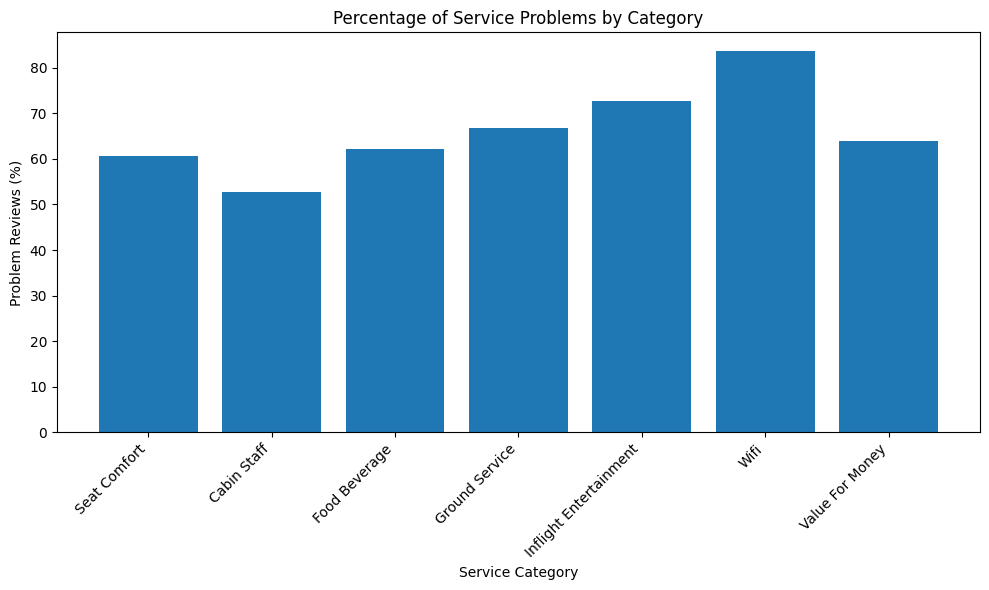

In [22]:
#Visualize Problem Rates

plot_data = target_summary.copy()

plot_data['Service'] = (
    plot_data['Target']
    .str.replace('_Problem', '', regex=False)
    .str.replace('_', ' ', regex=False)
)

plt.figure(figsize=(10, 6))

plt.bar(
    plot_data['Service'],
    plot_data['Problem %']
)

plt.ylabel('Problem Reviews (%)')
plt.xlabel('Service Category')
plt.title('Percentage of Service Problems by Category')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

>>The percentage of problem ratings differs substantially across service categories, so class imbalance needs to be considered when evaluating the models.

 ### Correlation Between Service-Problem Labels:  
 >>Because a single passenger review may describe more than one service issue,
the relationships among the seven service-problem labels were examined.A correlation matrix provides an exploratory view of whether certain types of service problems tend to occur together. Correlation indicates association, not causation.

In [44]:
# Correlation among service-problem target labels

target_columns = [
    'Seat_Comfort_Problem',
    'Cabin_Staff_Problem',
    'Food_Beverage_Problem',
    'Ground_Service_Problem',
    'Inflight_Entertainment_Problem',
    'Wifi_Problem',
    'Value_For_Money_Problem'
]

target_corr = df[target_columns].corr()

target_corr.round(2)

,Seat_Comfort_Problem,Cabin_Staff_Problem,Food_Beverage_Problem,Ground_Service_Problem,Inflight_Entertainment_Problem,Wifi_Problem,Value_For_Money_Problem
Seat_Comfort_Problem,1.00,0.81,0.80,0.80,0.67,0.69,0.85
Cabin_Staff_Problem,0.81,1.00,0.80,0.75,0.61,0.62,0.80
Food_Beverage_Problem,0.80,0.80,1.00,0.76,0.72,0.73,0.83
Ground_Service_Problem,0.80,0.75,0.76,1.00,0.65,0.66,0.86
Inflight_Entertainment_Problem,0.67,0.61,0.72,0.65,1.00,0.81,0.65
Wifi_Problem,0.69,0.62,0.73,0.66,0.81,1.00,0.71
Value_For_Money_Problem,0.85,0.80,0.83,0.86,0.65,0.71,1.00


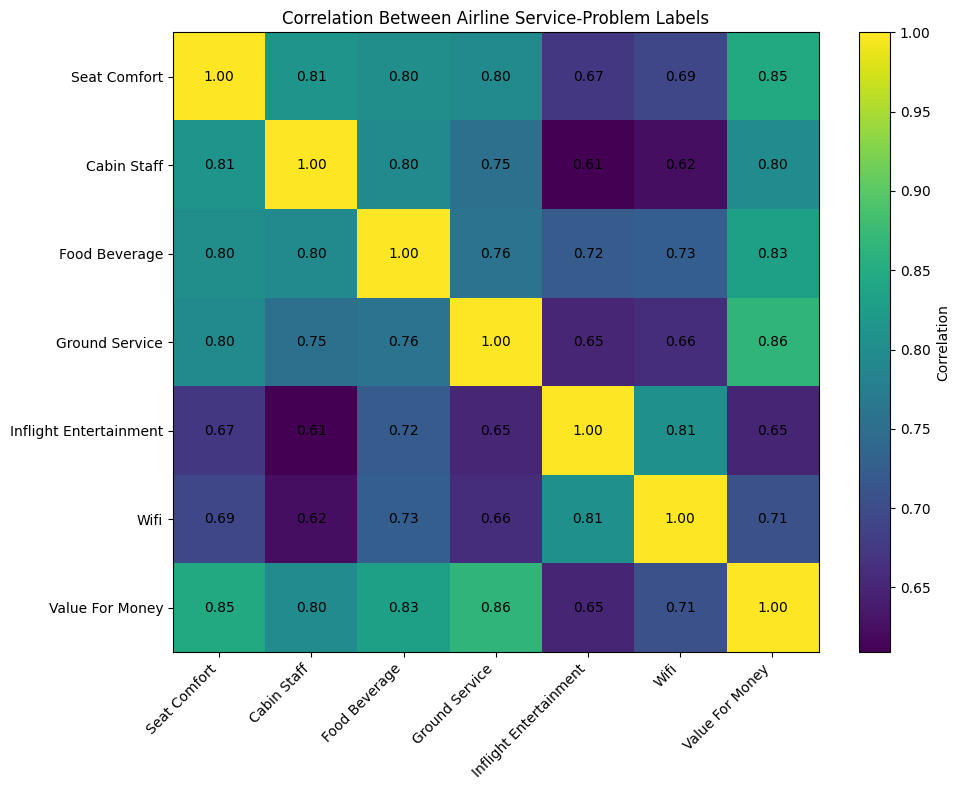

In [45]:
###Plot

plt.figure(figsize=(10, 8))

plt.imshow(
    target_corr,
    aspect='auto'
)

plt.colorbar(label='Correlation')

plt.xticks(
    range(len(target_columns)),
    [x.replace('_Problem', '').replace('_', ' ') for x in target_columns],
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(target_columns)),
    [x.replace('_Problem', '').replace('_', ' ') for x in target_columns]
)

# Add correlation values inside the cells
for i in range(len(target_columns)):
    for j in range(len(target_columns)):
        value = target_corr.iloc[i, j]

        if not np.isnan(value):
            plt.text(
                j,
                i,
                f'{value:.2f}',
                ha='center',
                va='center'
            )

plt.title('Correlation Between Airline Service-Problem Labels')

plt.tight_layout()
plt.show()

>> The correlation matrix helps identify categories that are associated, although correlation does not imply that one problem causes another

### NLP Text Cleaning

In [23]:
stop_words = set(stopwords.words('english'))

# Keep important negation words
stop_words = stop_words - {'no', 'nor', 'not'}

lemmatizer = WordNetLemmatizer()


def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(
        r'http\S+|www\S+',
        ' ',
        text
    )

    # Keep letters and spaces only
    text = re.sub(
        r'[^a-z\s]',
        ' ',
        text
    )

    # Remove extra spaces
    text = re.sub(
        r'\s+',
        ' ',
        text
    ).strip()

    words = text.split()

    # Remove stopwords and lemmatize
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
        and len(word) > 2
    ]

    return ' '.join(words)

In [24]:
#Apply Text Cleaning

df['Clean_Review'] = (
    df['Review']
    .apply(clean_text)
)

df[
    ['Review', 'Clean_Review']
].head()

,Review,Clean_Review
0,Moroni to Moheli. Turned out to be a pretty ...,moroni moheli turned pretty decent airline onl...
1,Moroni to Anjouan. It is a very small airline...,moroni anjouan small airline ticket advised tu...
2,Anjouan to Dzaoudzi. A very small airline an...,anjouan dzaoudzi small airline airline based c...
3,Please do a favor yourself and do not fly wi...,please favor not fly adria route munich pristi...
4,Do not book a flight with this airline! My fr...,not book flight airline friend returned sofia ...


In [26]:
#Check Cleaned Review Length

df['Review_Word_Count'] = (
    df['Clean_Review']
    .str.split()
    .str.len()
)

df['Review_Word_Count'].describe()

count    23051.000000
mean        65.237517
std         47.367963
min          2.000000
25%         33.000000
50%         51.000000
75%         81.000000
max        576.000000
Name: Review_Word_Count, dtype: float64

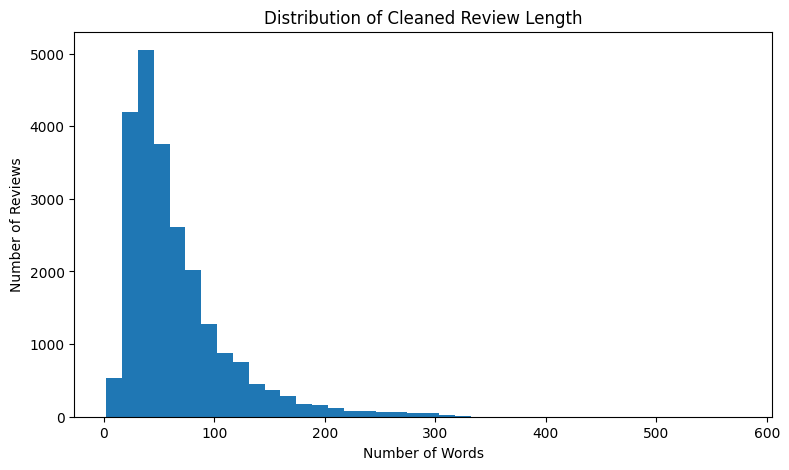

In [27]:
plt.figure(figsize=(9, 5))

plt.hist(
    df['Review_Word_Count'],
    bins=40
)

plt.xlabel('Number of Words')
plt.ylabel('Number of Reviews')
plt.title('Distribution of Cleaned Review Length')

plt.show()

### Word Cloud Analysis

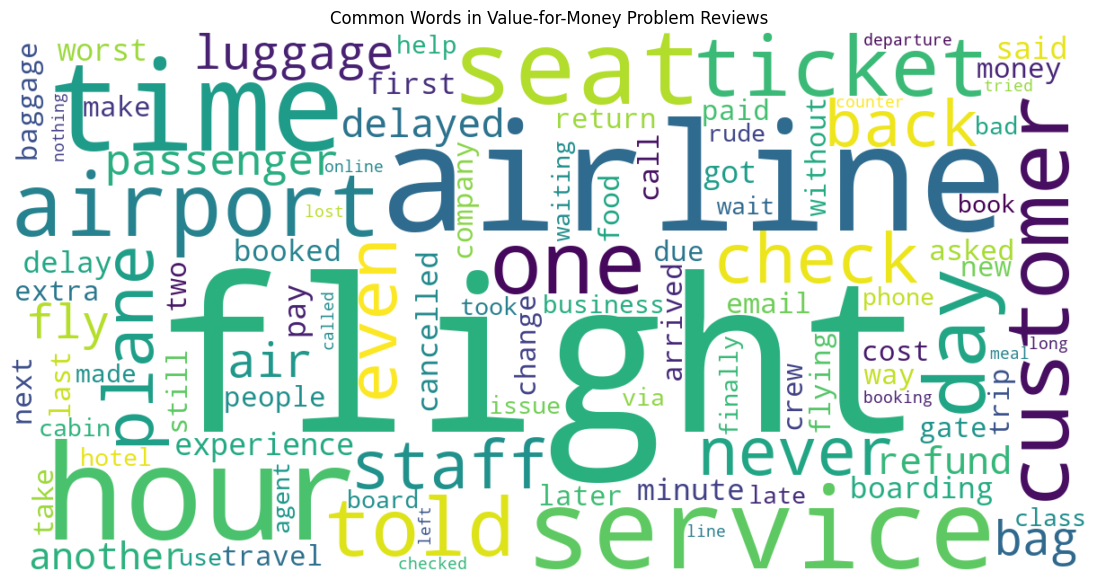

In [28]:
problem_text = ' '.join(
    df.loc[
        df['Value_For_Money_Problem'] == 1,
        'Clean_Review'
    ].dropna()
)

problem_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100,
    collocations=False
).generate(problem_text)

plt.figure(figsize=(14, 7))

plt.imshow(
    problem_wordcloud,
    interpolation='bilinear'
)

plt.axis('off')

plt.title(
    'Common Words in Value-for-Money Problem Reviews'
)

plt.show()

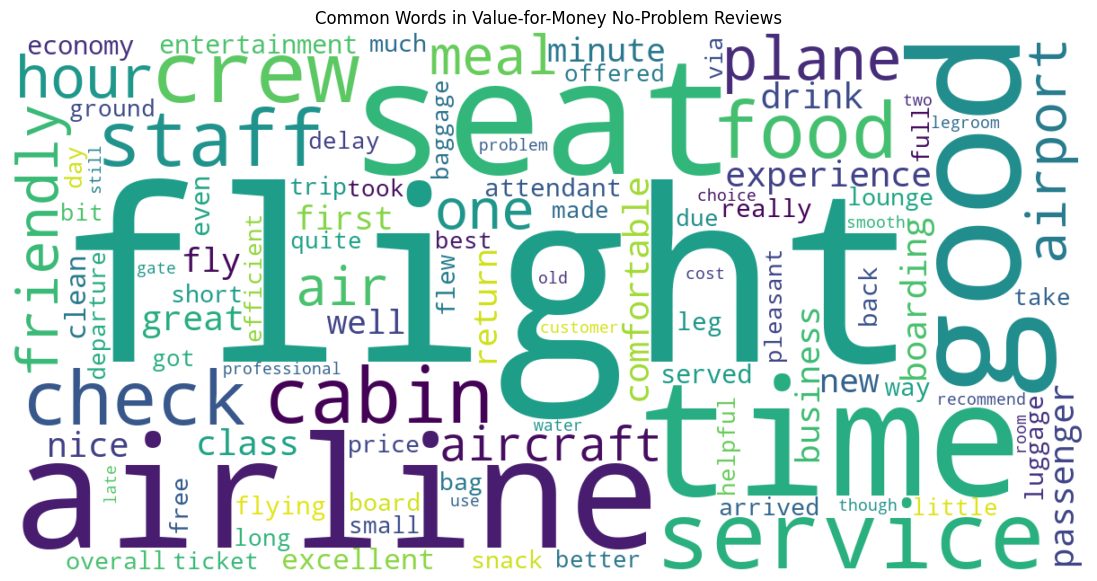

In [29]:
##No-Problem Word Cloud


positive_text = ' '.join(
    df.loc[
        df['Value_For_Money_Problem'] == 0,
        'Clean_Review'
    ].dropna()
)

positive_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100,
    collocations=False
).generate(positive_text)

plt.figure(figsize=(14, 7))

plt.imshow(
    positive_wordcloud,
    interpolation='bilinear'
)

plt.axis('off')

plt.title(
    'Common Words in Value-for-Money No-Problem Reviews'
)

plt.show()

Word clouds provide an exploratory visualization of frequently occurring terms.

They should not be interpreted as statistical evidence. Their purpose is to provide
an intuitive view of the vocabulary appearing in problem and no-problem reviews.

A quantitative term-frequency analysis is therefore included next.

### Top Words — Better Than Word Cloud Alone

In [30]:
def get_top_terms(text_series, n=15):

    vectorizer = CountVectorizer(
        stop_words=None,
        max_features=5000
    )

    matrix = vectorizer.fit_transform(
        text_series.dropna()
    )

    frequencies = np.asarray(
        matrix.sum(axis=0)
    ).flatten()

    terms = vectorizer.get_feature_names_out()

    result = pd.DataFrame({
        'Term': terms,
        'Frequency': frequencies
    })

    return (
        result
        .sort_values(
            'Frequency',
            ascending=False
        )
        .head(n)
    )

In [31]:
problem_top_words = get_top_terms(
    df.loc[
        df['Value_For_Money_Problem'] == 1,
        'Clean_Review'
    ],
    n=15
)

problem_top_words

,Term,Frequency
1736,flight,30209
2960,not,17290
132,airline,12397
2095,hour,9387
4489,time,8313
3946,service,7434
3892,seat,6325
136,airport,5854
4960,would,5814
1123,customer,5731


### Plot Top Problem Words

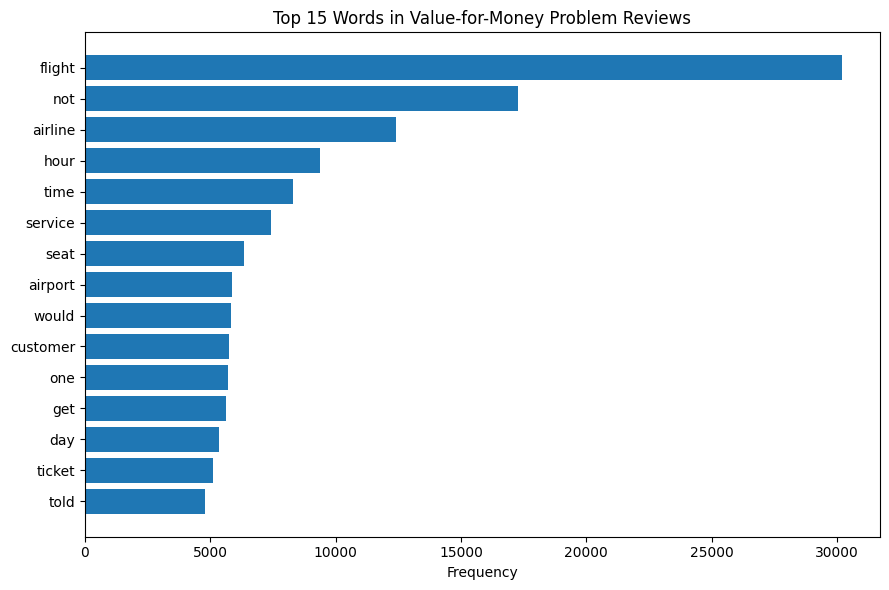

In [32]:
plot_words = (
    problem_top_words
    .sort_values('Frequency')
)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_words['Term'],
    plot_words['Frequency']
)

plt.xlabel('Frequency')

plt.title(
    'Top 15 Words in Value-for-Money Problem Reviews'
)

plt.tight_layout()
plt.show()

###  Bigrams

In [33]:
def get_top_bigrams(text_series, n=15):

    vectorizer = CountVectorizer(
        ngram_range=(2, 2),
        max_features=5000
    )

    matrix = vectorizer.fit_transform(
        text_series.dropna()
    )

    frequencies = np.asarray(
        matrix.sum(axis=0)
    ).flatten()

    terms = vectorizer.get_feature_names_out()

    result = pd.DataFrame({
        'Bigram': terms,
        'Frequency': frequencies
    })

    return (
        result
        .sort_values(
            'Frequency',
            ascending=False
        )
        .head(n)
    )

In [34]:
problem_bigrams = get_top_bigrams(
    df.loc[
        df['Value_For_Money_Problem'] == 1,
        'Clean_Review'
    ],
    n=15
)

problem_bigrams

,Bigram,Frequency
1078,customer service,3485
1680,flight delayed,1424
969,connecting flight,1036
687,business class,1005
1653,flight cancelled,994
4901,worst airline,957
1014,could not,951
4954,would not,904
3753,return flight,903
2915,never fly,894


## Multi-Label Modeling Strategy

The project is a multi-label classification problem because one passenger review
may be associated with multiple service problems.

For the TF-IDF and Logistic Regression baseline, the multi-label problem is
implemented using a binary relevance approach. A separate binary classifier is
trained for each service category.

For example, one review may independently be classified as:

- Seat Comfort Problem = 1
- Ground Service Problem = 1
- Cabin Staff Problem = 0

This allows multiple service problems to be assigned to the same passenger review.

### Logistic Regression Modeling

Machine-Learning Model: 

TF-IDF converts review text into numerical features by assigning greater importance
to terms that are informative within individual reviews but less common across the
entire collection.

Logistic Regression is used as the primary classifier because it performs well with
high-dimensional sparse text data and is relatively interpretable.

A separate model is trained for each of the seven service-problem categories.

### Train Logistic Regression

In [35]:
##Train model


def train_logistic_model(df, target_col):

    # Keep only reviews with a known target
    model_df = (
        df[
            ['Clean_Review', target_col]
        ]
        .dropna()
        .copy()
    )

    X = model_df['Clean_Review']

    y = (
        model_df[target_col]
        .astype(int)
    )

    print("\n" + "=" * 60)
    print("TARGET:", target_col)
    print("=" * 60)

    print("Usable rows:", len(model_df))

    print("\nClass distribution:")
    print(y.value_counts())

    # 80/20 stratified split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    # TF-IDF
    tfidf = TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=3,
        max_df=0.95,
        sublinear_tf=True
    )

    X_train_tfidf = tfidf.fit_transform(
        X_train
    )

    X_test_tfidf = tfidf.transform(
        X_test
    )

    # Logistic Regression
    model = LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    )

    model.fit(
        X_train_tfidf,
        y_train
    )

    predictions = model.predict(
        X_test_tfidf
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    print("\nAccuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")

    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )

    return {
        'model': model,
        'vectorizer': tfidf,
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'predictions': predictions,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1
    }

In [36]:
###Train All Seven Models

logistic_results = {}

for target in target_columns:

    logistic_results[target] = (
        train_logistic_model(
            df,
            target
        )
    )


TARGET: Seat_Comfort_Problem
Usable rows: 15391

Class distribution:
Seat_Comfort_Problem
1    9345
0    6046
Name: count, dtype: int64

Accuracy : 0.8941
Precision: 0.908
Recall   : 0.9187
F1 Score : 0.9133

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.86      1210
           1       0.91      0.92      0.91      1869

    accuracy                           0.89      3079
   macro avg       0.89      0.89      0.89      3079
weighted avg       0.89      0.89      0.89      3079


TARGET: Cabin_Staff_Problem
Usable rows: 16057

Class distribution:
Cabin_Staff_Problem
1    8458
0    7599
Name: count, dtype: int64

Accuracy : 0.8611
Precision: 0.8408
Recall   : 0.9084
F1 Score : 0.8733

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.81      0.85      1520
           1       0.84      0.91      0.87      1692

    accuracy                           0.86 

### Model Summary Table

In [37]:
logistic_summary = pd.DataFrame([
    {
        'Target': target,
        'Accuracy': result['accuracy'],
        'Precision': result['precision'],
        'Recall': result['recall'],
        'F1 Score': result['f1']
    }

    for target, result
    in logistic_results.items()
])

logistic_summary.round(4)

,Target,Accuracy,Precision,Recall,F1 Score
0,Seat_Comfort_Problem,0.8941,0.9080,0.9187,0.9133
1,Cabin_Staff_Problem,0.8611,0.8408,0.9084,0.8733
2,Food_Beverage_Problem,0.8882,0.9155,0.9033,0.9094
3,Ground_Service_Problem,0.9164,0.9481,0.9254,0.9367
4,Inflight_Entertainment_Problem,0.8373,0.9038,0.8691,0.8861
5,Wifi_Problem,0.8896,0.9529,0.9130,0.9325
6,Value_For_Money_Problem,0.9266,0.9500,0.9343,0.9421


In [38]:
#Sort by F1


logistic_summary.sort_values(
    by='F1 Score',
    ascending=False
).round(4)

,Target,Accuracy,Precision,Recall,F1 Score
6,Value_For_Money_Problem,0.9266,0.9500,0.9343,0.9421
3,Ground_Service_Problem,0.9164,0.9481,0.9254,0.9367
5,Wifi_Problem,0.8896,0.9529,0.9130,0.9325
0,Seat_Comfort_Problem,0.8941,0.9080,0.9187,0.9133
2,Food_Beverage_Problem,0.8882,0.9155,0.9033,0.9094
4,Inflight_Entertainment_Problem,0.8373,0.9038,0.8691,0.8861
1,Cabin_Staff_Problem,0.8611,0.8408,0.9084,0.8733


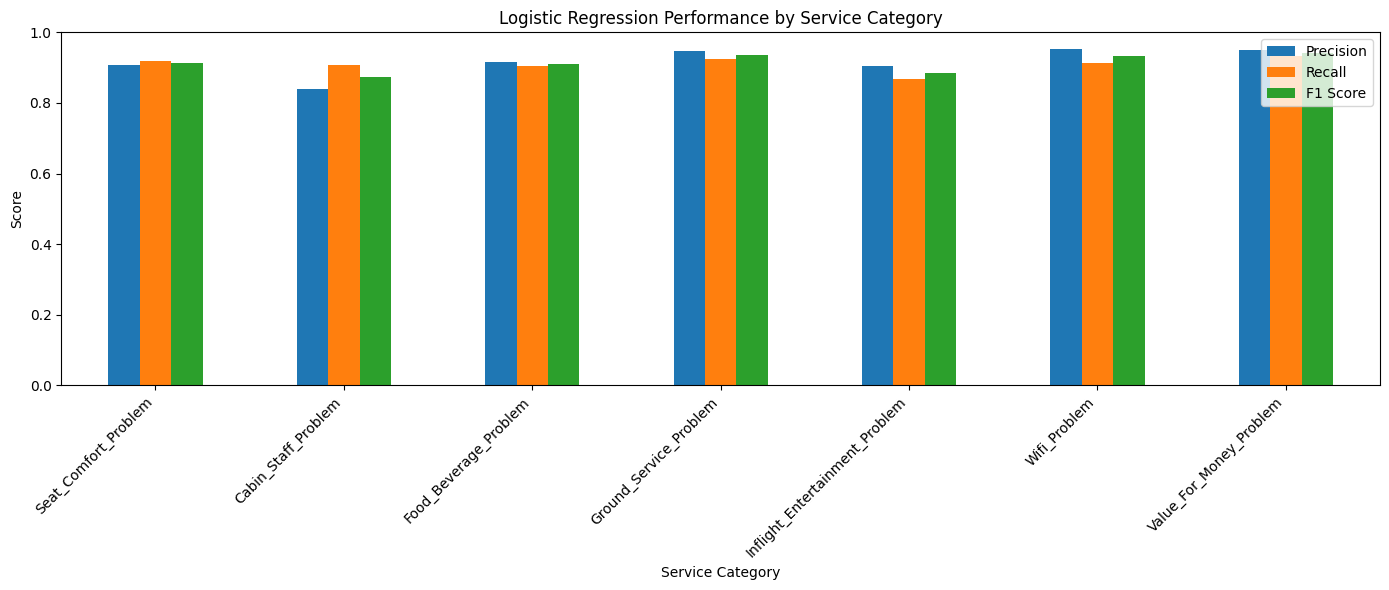

In [39]:
### Model Performance Graph

plot_df = (
    logistic_summary
    .set_index('Target')[
        ['Precision', 'Recall', 'F1 Score']
    ]
)

plot_df.plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title(
    'Logistic Regression Performance by Service Category'
)

plt.ylabel('Score')
plt.xlabel('Service Category')

plt.ylim(0, 1)

plt.xticks(
    rotation=45,
    ha='right'
)

plt.tight_layout()
plt.show()

### Confusion Matrices


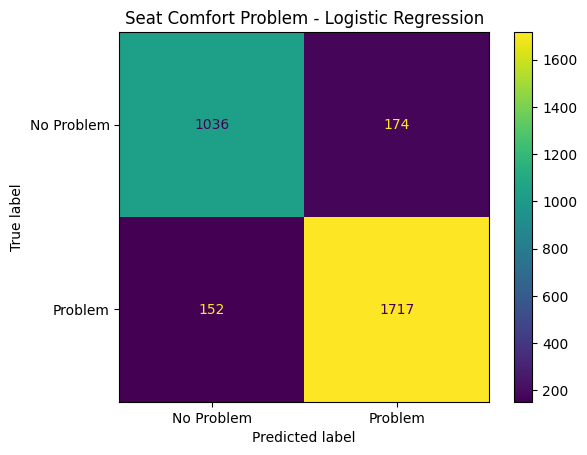

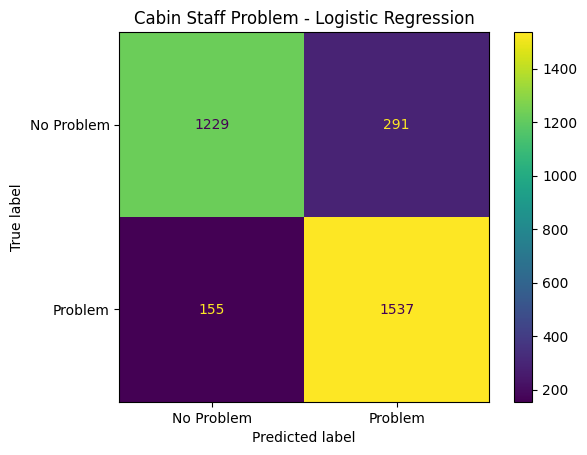

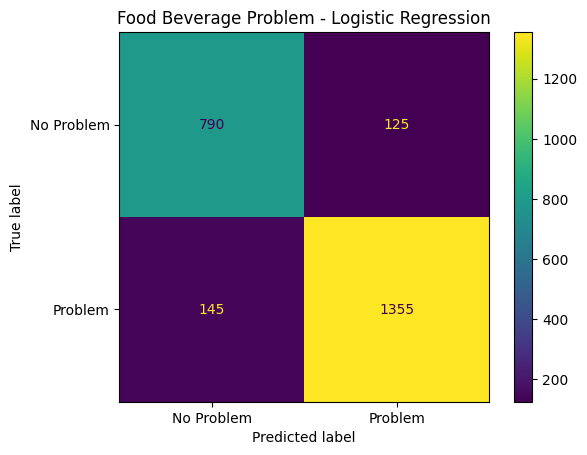

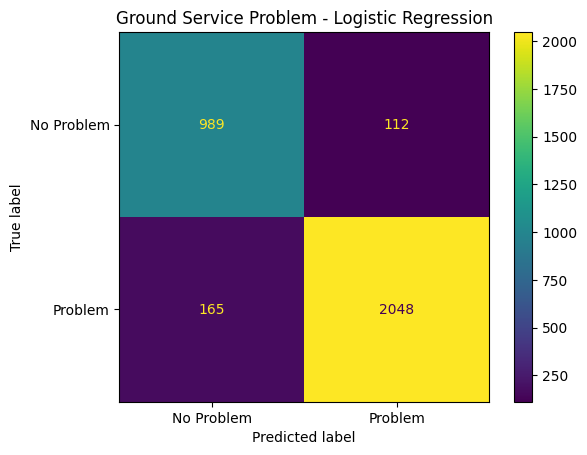

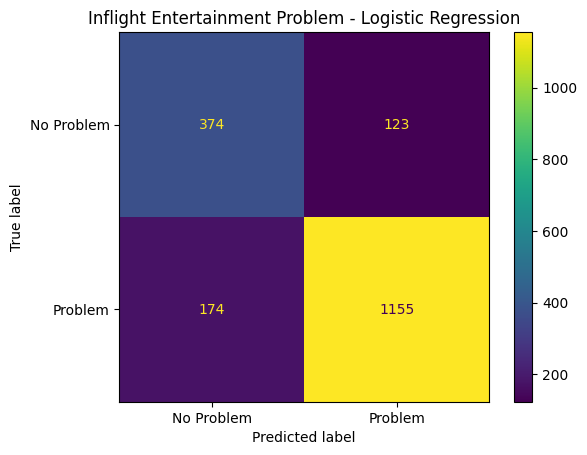

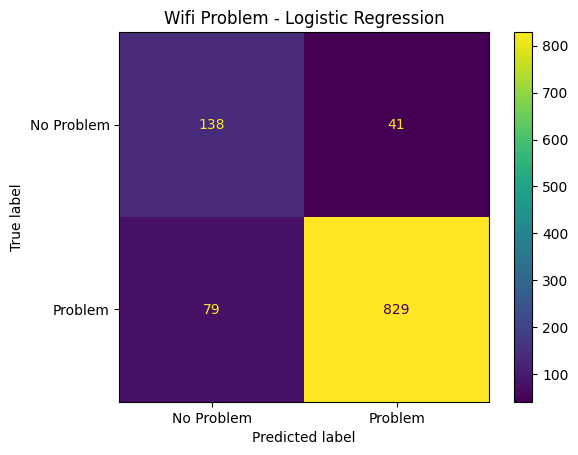

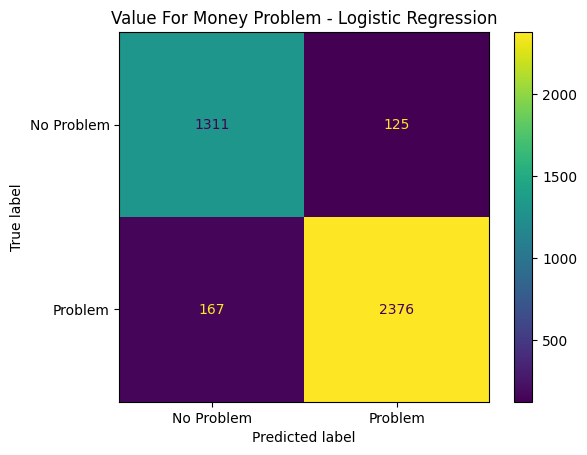

In [40]:
for target, result in logistic_results.items():

    cm = confusion_matrix(
        result['y_test'],
        result['predictions']
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            'No Problem',
            'Problem'
        ]
    )

    disp.plot()

    plt.title(
        target.replace('_', ' ')
        + ' - Logistic Regression'
    )

    plt.show()

### Important Words Learned by the Model

In [41]:
def get_model_terms(
    logistic_results,
    target,
    n=15
):

    result = logistic_results[target]

    model = result['model']
    vectorizer = result['vectorizer']

    features = (
        vectorizer
        .get_feature_names_out()
    )

    coefficients = (
        model.coef_[0]
    )

    coefficient_df = pd.DataFrame({
        'Term': features,
        'Coefficient': coefficients
    })

    problem_terms = (
        coefficient_df
        .sort_values(
            'Coefficient',
            ascending=False
        )
        .head(n)
    )

    no_problem_terms = (
        coefficient_df
        .sort_values(
            'Coefficient',
            ascending=True
        )
        .head(n)
    )

    return problem_terms, no_problem_terms

In [42]:
## Example — Value for Money


problem_terms, no_problem_terms = (
    get_model_terms(
        logistic_results,
        'Value_For_Money_Problem',
        n=15
    )
)

print("Terms associated with problems:")
display(problem_terms)

print("\nTerms associated with no problem:")
display(no_problem_terms)

Terms associated with problems:


,Term,Coefficient
9858,worst,5.713667
5968,not,5.246363
5832,never,4.853344
7548,rude,3.693550
9045,told,3.624478
6870,poor,3.567198
4459,hour,3.268319
8750,terrible,3.239439
6603,pay,2.877888
2200,customer,2.785417



Terms associated with no problem:


,Term,Coefficient
4122,good,-7.041767
3000,excellent,-5.736943
4205,great,-5.439649
8771,thank,-5.386136
1819,comfortable,-4.840818
3888,friendly,-4.839317
5910,nice,-4.753515
4359,helpful,-4.404163
6825,pleasant,-3.515648
2703,easy,-3.350685


### Plot Important Problem Terms

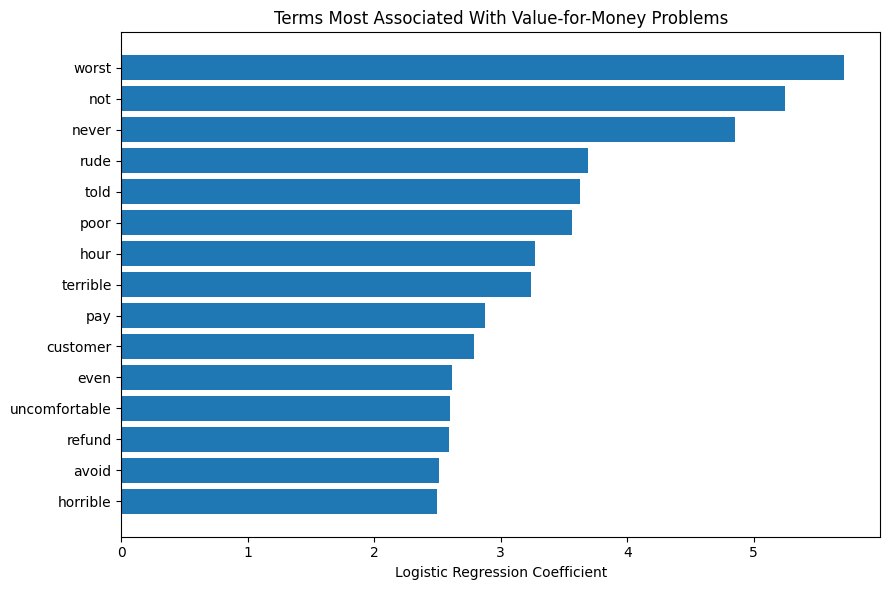

In [43]:
plot_terms = (
    problem_terms
    .sort_values('Coefficient')
)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_terms['Term'],
    plot_terms['Coefficient']
)

plt.xlabel('Logistic Regression Coefficient')

plt.title(
    'Terms Most Associated With Value-for-Money Problems'
)

plt.tight_layout()
plt.show()

### Class Imbalance

Prediction performance should not be evaluated using accuracy alone.

Some service categories, especially Wi-Fi & Connectivity, contain substantially more
problem observations than no-problem observations.

For this reason:

- Stratified train/test splitting was used.
- Logistic Regression used `class_weight='balanced'`.
- Precision, recall and F1 score were examined in addition to accuracy.
- Class-specific performance in the classification reports and confusion matrices
  was also considered.

A high overall F1 score does not necessarily mean that both classes are predicted
equally well. For example, Wi-Fi contains relatively few no-problem observations,
which makes prediction of that minority class more difficult.




### Major Findings

The NLP models indicate that passenger review text contains substantial information
about specific airline service experiences.

Logistic Regression with TF-IDF achieved strong F1 scores across all seven service
categories.

Performance varied across categories. Value for Money and Ground Service showed
particularly strong prediction performance, while Cabin Staff Service and Inflight
Entertainment were relatively more difficult to classify.

The differences in performance may reflect several factors, including:

- differences in available training data,
- differences in class balance,
- how directly passengers describe particular service experiences,
- and overlap between different service issues within a single review.

Wi-Fi requires special interpretation because it contains substantially fewer usable
ratings and a highly imbalanced target distribution.

Exploratory word clouds, term-frequency analysis, bigrams and Logistic Regression
coefficients help identify language patterns associated with passenger dissatisfaction.


### Limitations

This analysis has several limitations.

1. Service-problem labels were derived from numerical passenger ratings rather than
   manually labeled review sentences.

2. Rating 3 was treated as neutral and excluded from binary classification.

3. Some service categories contain substantial missing data.

4. Reviews may discuss multiple service issues simultaneously, making individual
   service categories difficult to separate perfectly.

5. Class imbalance is substantial for some targets, particularly Wi-Fi & Connectivity.

6. Word clouds represent frequency rather than statistical importance.

7. The analysis uses TF-IDF, which represents word importance but does not fully
   capture sentence context or word order.

8. The dataset contains reviews over a long period of time, and airline service
   patterns may have changed during that period.

### Future Work

Future research could extend this project by:

- comparing Logistic Regression with additional traditional text classifiers,
  such as Linear Support Vector Machines or Naive Bayes;

- evaluating deep-learning approaches such as Bidirectional Long Short-Term Memory
  (BiLSTM) networks;

- investigating transformer-based language models;

- analyzing airline-specific differences;

- examining changes in passenger concerns over time;

- incorporating passenger type, seat type and verified-review information;

- and developing a multi-label system capable of identifying several service problems
  simultaneously from a single review.

#### Conclusion

This project demonstrates that Natural Language Processing can be used to identify
specific airline service problems from passenger review text.

After cleaning approximately 23,000 unique airline reviews, seven binary
service-problem targets were created from passenger service ratings.

Review text was transformed using TF-IDF and classified using Logistic Regression.
The models achieved strong precision, recall and F1 scores across the seven service
categories.

The analysis also showed that model performance should be interpreted together with
data availability and class balance. Some service categories contain substantially
more missing or imbalanced observations than others.

The results suggest that automated text analysis could help airlines summarize large
volumes of customer feedback and identify recurring service concerns without requiring
every review to be manually examined.